# Perturbability vs. PANSS model performance

Validates perturbability *through* the PANSS model rather than against PANSS directly: does a subject's perturbability relate to how well the fixed Ridge + Ftau (threshold=0.2) model predicts them?

Self-contained: recomputes the same fixed matrix-element subset + Ridge LOOCV model from `panss_model_region_overfit.ipynb` (Ftau only, threshold=0.2), then correlates each subject's LOOCV absolute error with:
- `max(p2o)`: the strongest perturbation-to-origin across regions.
- `min(p2h)`: the strongest perturbation-to-healthy across regions.

See `perturbability_panss_correlation.ipynb` for the direct perturbability-vs-PANSS check.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Load data

In [2]:
# fmri timeseries
fmri = np.load('./data/HCP_early_psychosis_timeseries_cleaned.npz')
ts_ap = fmri['ts_ap']
ts_nap = fmri['ts_nap']

# clinical scores
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]

# Perturbability maps: per-region (100,) scores per subject, keyed by group then subject index
p2h_maps = np.load("./data/p2h_maps.pkl", allow_pickle=True)
p2o_maps = np.load("./data/p2o_maps.pkl", allow_pickle=True)

## Fixed Ridge + Ftau model (threshold=0.2)

Same design as `panss_model_region_overfit.ipynb`: every off-diagonal Ftau matrix element is a candidate feature, correlated with PANSS across all subjects, and the `|corr| > 0.2` subset is fixed once and fit with `RidgeCV`, evaluated by LOOCV.

In [3]:
def compute_ftau_matrix(sub_ts, tau=1):
    """Lag-tau (empirical) functional connectivity matrix."""
    n_regions = sub_ts.shape[0]
    ts_t0 = sub_ts[:, :-tau]
    ts_ttau = sub_ts[:, tau:]
    full_corr = np.corrcoef(ts_t0, ts_ttau)
    return full_corr[:n_regions, n_regions:]


def offdiag_mask(n):
    """Boolean mask selecting every off-diagonal position of an n x n matrix."""
    return ~np.eye(n, dtype=bool)


def flatten_offdiag_features(matrix):
    """Every off-diagonal element of the connectivity matrix, flattened to one feature vector."""
    mat = np.nan_to_num(matrix)
    return mat[offdiag_mask(mat.shape[0])]


def build_ftau_dataset():
    """Assemble X, y: every off-diagonal Ftau element as a feature, pooling AP-then-NAP."""
    X_list, y_list = [], []

    for group, ts_array, panss in (("AP", ts_ap, panss_AP), ("NAP", ts_nap, panss_NAP)):
        for idx in range(ts_array.shape[0]):
            matrix = compute_ftau_matrix(ts_array[idx, :, :], tau=1)
            X_list.append(flatten_offdiag_features(matrix))
            y_list.append(panss[idx])

    X = np.array(X_list)
    y = np.array(y_list)

    valid_mask = ~np.isnan(y)
    return X[valid_mask], y[valid_mask]


def select_fixed_features(X, y, threshold):
    """Full-sample correlation-threshold feature selection, fixed once across all subjects."""
    corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])
    corrs = np.nan_to_num(corrs)
    selected = np.where(np.abs(corrs) > threshold)[0]

    if selected.size == 0:
        selected = np.array([np.argmax(np.abs(corrs))])

    return selected


def run_ridge_loocv(X, y):
    """RidgeCV evaluated by LOOCV: refit per fold on the training subjects, predict the held-out subject."""
    loo = LeaveOneOut()
    y_true_all, y_pred_all = [], []

    for train_index, test_index in loo.split(X):
        model = RidgeCV(alphas=np.logspace(-3, 3, 13))
        model.fit(X[train_index], y[train_index])
        pred = model.predict(X[test_index])

        y_true_all.append(y[test_index][0])
        y_pred_all.append(pred[0])

    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    corr, pval = pearsonr(y_true_all, y_pred_all)

    return {
        "y_true": y_true_all,
        "y_pred": y_pred_all,
        "rmse": np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
        "mae": mean_absolute_error(y_true_all, y_pred_all),
        "r2": r2_score(y_true_all, y_pred_all),
        "corr": corr,
        "pval": pval,
    }

In [4]:
X, y = build_ftau_dataset()
selected_idx = select_fixed_features(X, y, threshold=0.2)
loocv = run_ridge_loocv(X[:, selected_idx], y)

print(f"Selected {len(selected_idx)} / {X.shape[1]} matrix elements (fixed across all subjects)")
print(f"LOOCV R2   = {loocv['r2']:.4f}")
print(f"LOOCV RMSE = {loocv['rmse']:.4f}")
print(f"LOOCV MAE  = {loocv['mae']:.4f}")
print(f"Corr(y, yhat) = {loocv['corr']:.4f}  (p={loocv['pval']:.4f})")

Selected 233 / 9900 matrix elements (fixed across all subjects)
LOOCV R2   = 0.3142
LOOCV RMSE = 9.2601
LOOCV MAE  = 7.4926
Corr(y, yhat) = 0.5644  (p=0.0000)


## Per-subject perturbability summary

`sklearn.LeaveOneOut` yields folds in row order, so `loocv["y_true"][k]` / `loocv["y_pred"][k]` correspond to the same subject as row `k` of `X` — i.e. the same AP-then-NAP, valid-PANSS-only ordering as `build_ftau_dataset()`. Building the perturbability summary with that identical pooling/filtering keeps everything aligned by subject.

In [5]:
def build_perturbability_summary():
    """
    Per-subject max(p2o) and min(p2h) across regions ("most significant
    perturbation"), pooled AP-then-NAP with the same valid-PANSS filtering
    as build_ftau_dataset(), so rows line up with loocv["y_true"]/["y_pred"].
    """
    max_p2o_list, min_p2h_list, y_list = [], [], []

    for group, panss in (("AP", panss_AP), ("NAP", panss_NAP)):
        for idx in range(len(panss)):
            max_p2o_list.append(np.max(p2o_maps[group][idx]))
            min_p2h_list.append(np.min(p2h_maps[group][idx]))
            y_list.append(panss[idx])

    max_p2o = np.array(max_p2o_list)
    min_p2h = np.array(min_p2h_list)
    y_check = np.array(y_list)

    valid_mask = ~np.isnan(y_check)
    return max_p2o[valid_mask], min_p2h[valid_mask]


max_p2o, min_p2h = build_perturbability_summary()
assert len(max_p2o) == len(loocv["y_true"])

## Correlate model performance with perturbability

"Performance" per subject = LOOCV absolute error `|y_true - y_pred|` (lower = model predicted that subject better).

max(p2o) vs |LOOCV error|: r = 0.0350, p = 0.7405
min(p2h) vs |LOOCV error|: r = -0.1105, p = 0.2944


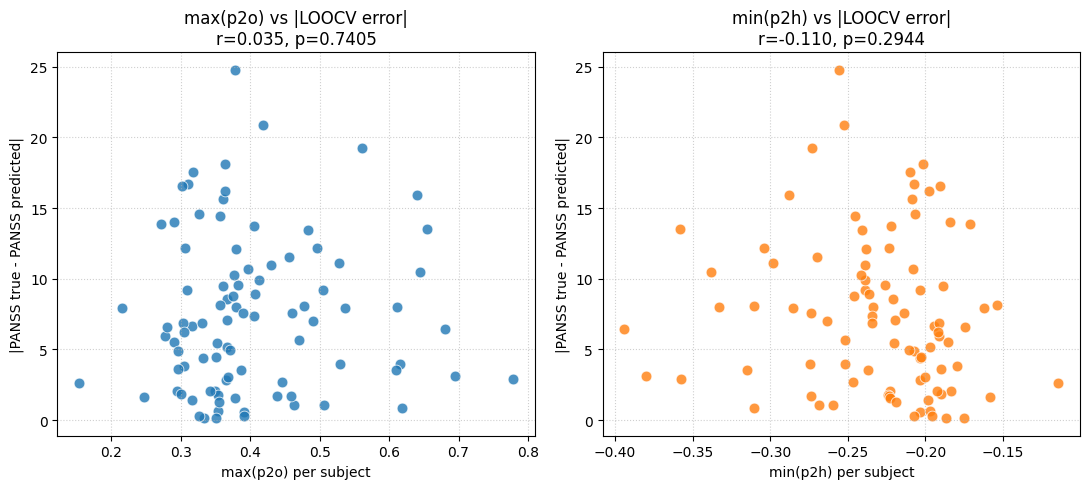

In [6]:
abs_error = np.abs(loocv["y_true"] - loocv["y_pred"])

r_p2o, p_p2o = pearsonr(max_p2o, abs_error)
r_p2h, p_p2h = pearsonr(min_p2h, abs_error)

print(f"max(p2o) vs |LOOCV error|: r = {r_p2o:.4f}, p = {p_p2o:.4f}")
print(f"min(p2h) vs |LOOCV error|: r = {r_p2h:.4f}, p = {p_p2h:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

sns.scatterplot(x=max_p2o, y=abs_error, ax=axes[0], color='#1f77b4', s=60, alpha=0.8)
axes[0].set_title(f'max(p2o) vs |LOOCV error|\nr={r_p2o:.3f}, p={p_p2o:.4f}')
axes[0].set_xlabel('max(p2o) per subject')
axes[0].set_ylabel('|PANSS true - PANSS predicted|')
axes[0].grid(True, linestyle=':', alpha=0.6)

sns.scatterplot(x=min_p2h, y=abs_error, ax=axes[1], color='#ff7f0e', s=60, alpha=0.8)
axes[1].set_title(f'min(p2h) vs |LOOCV error|\nr={r_p2h:.3f}, p={p_p2h:.4f}')
axes[1].set_xlabel('min(p2h) per subject')
axes[1].set_ylabel('|PANSS true - PANSS predicted|')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()